# Nettoyage de données — Indicateurs de santé au Tchad

**Objectif :** Collecter, nettoyer et préparer un jeu de données de 10 indicateurs de santé pour le Tchad (2000–2023) à partir de l'API de la Banque Mondiale.

**Source :** [World Bank Open Data](https://data.worldbank.org) — API REST v2

**Auteur :** Steven Barde — [github.com/barde44](https://github.com/barde44)

## 1. Configuration et imports

In [20]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

RAW_DIR = Path('../dataset/raw')
CLEAN_DIR = Path('../dataset/cleaned')
IMG_DIR = Path('../images')

for d in [RAW_DIR, CLEAN_DIR, IMG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

COUNTRY = 'TCD'
YEAR_START = 2000
YEAR_END = 2023

## 2. Collecte des données (API Banque Mondiale)

In [21]:
INDICATORS = {
    'SH.DYN.MORT': 'mortalite_infantile_pour_1000',
    'SH.STA.STNT.ZS': 'retard_croissance_pct',
    'SH.STA.WAST.ZS': 'emaciation_pct',
    'SH.IMM.MEAS': 'vaccination_rougeole_pct',
    'SH.IMM.IDPT': 'vaccination_dpt_pct',
    'SP.DYN.LE00.IN': 'esperance_vie_annees',
    'SH.XPD.CHEX.PP.CD': 'depenses_sante_usd_hab',
    'SH.MED.PHYS.ZS': 'medecins_pour_1000',
    'SH.MED.BEDS.ZS': 'lits_hopital_pour_1000',
    'SH.STA.MMRT': 'mortalite_maternelle_pour_100k'
}

print(f'{len(INDICATORS)} indicateurs à collecter pour {COUNTRY} ({YEAR_START}-{YEAR_END})')

10 indicateurs à collecter pour TCD (2000-2023)


In [22]:
def fetch_indicator(country, indicator_code, start_year, end_year):
    """Récupère un indicateur depuis l'API Banque Mondiale."""
    url = (
        f'https://api.worldbank.org/v2/country/{country}'
        f'/indicator/{indicator_code}'
        f'?date={start_year}:{end_year}&format=json&per_page=500'
    )
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    data = response.json()
    
    if len(data) < 2 or data[1] is None:
        return pd.DataFrame()
    
    records = []
    for entry in data[1]:
        records.append({
            'pays': entry['country']['value'],
            'code_pays': entry['countryiso3code'],
            'annee': entry['date'],
            'code_indicateur': entry['indicator']['id'],
            'indicateur': entry['indicator']['value'],
            'valeur': entry['value']
        })
    return pd.DataFrame(records)

frames = []
for code, name in INDICATORS.items():
    df_ind = fetch_indicator(COUNTRY, code, YEAR_START, YEAR_END)
    if not df_ind.empty:
        df_ind['nom_indicateur'] = name
        frames.append(df_ind)
        print(f'  ✓ {name}: {len(df_ind)} lignes, {df_ind["valeur"].notna().sum()} valeurs non-nulles')
    else:
        print(f'  ✗ {name}: aucune donnée')

df_raw = pd.concat(frames, ignore_index=True)
print(f'\nTotal: {len(df_raw)} lignes collectées')

  ✓ mortalite_infantile_pour_1000: 24 lignes, 24 valeurs non-nulles
  ✓ retard_croissance_pct: 24 lignes, 10 valeurs non-nulles
  ✓ emaciation_pct: 24 lignes, 10 valeurs non-nulles
  ✓ vaccination_rougeole_pct: 24 lignes, 24 valeurs non-nulles
  ✓ vaccination_dpt_pct: 24 lignes, 24 valeurs non-nulles
  ✓ esperance_vie_annees: 24 lignes, 24 valeurs non-nulles
  ✓ depenses_sante_usd_hab: 24 lignes, 24 valeurs non-nulles
  ✓ medecins_pour_1000: 24 lignes, 15 valeurs non-nulles
  ✓ lits_hopital_pour_1000: 24 lignes, 3 valeurs non-nulles
  ✓ mortalite_maternelle_pour_100k: 24 lignes, 24 valeurs non-nulles

Total: 240 lignes collectées


In [23]:
df_raw.to_csv(RAW_DIR / 'chad_health_indicators_raw.csv', index=False)
print(f'Données brutes sauvegardées: {RAW_DIR / "chad_health_indicators_raw.csv"}')

Données brutes sauvegardées: ..\dataset\raw\chad_health_indicators_raw.csv


## 3. Exploration des données brutes

In [24]:
print('=== DIMENSIONS ===')
print(f'Lignes: {df_raw.shape[0]}')
print(f'Colonnes: {df_raw.shape[1]}')
print(f'\n=== TYPES ===')
print(df_raw.dtypes)
print(f'\n=== APERÇU ===')
df_raw.head(10)

=== DIMENSIONS ===
Lignes: 240
Colonnes: 7

=== TYPES ===
pays                   str
code_pays              str
annee                  str
code_indicateur        str
indicateur             str
valeur             float64
nom_indicateur         str
dtype: object

=== APERÇU ===


,pays,code_pays,annee,code_indicateur,indicateur,valeur,nom_indicateur
0,Chad,TCD,2023,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",100.6,mortalite_infantile_pour_1000
1,Chad,TCD,2022,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",103.9,mortalite_infantile_pour_1000
2,Chad,TCD,2021,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",107.3,mortalite_infantile_pour_1000
3,Chad,TCD,2020,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",110.6,mortalite_infantile_pour_1000
4,Chad,TCD,2019,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",114.0,mortalite_infantile_pour_1000
5,Chad,TCD,2018,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",117.6,mortalite_infantile_pour_1000
6,Chad,TCD,2017,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",121.4,mortalite_infantile_pour_1000
7,Chad,TCD,2016,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",125.0,mortalite_infantile_pour_1000
8,Chad,TCD,2015,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",128.7,mortalite_infantile_pour_1000
9,Chad,TCD,2014,SH.DYN.MORT,"Mortality rate, under-5 (per 1,000 live births)",132.3,mortalite_infantile_pour_1000


In [25]:
print('=== VALEURS MANQUANTES ===')
missing = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().sum() / len(df_raw) * 100).round(1)
pd.DataFrame({'manquantes': missing, 'pourcentage': missing_pct})

=== VALEURS MANQUANTES ===


,manquantes,pourcentage
pays,0,0.0
code_pays,0,0.0
annee,0,0.0
code_indicateur,0,0.0
indicateur,0,0.0
valeur,58,24.2
nom_indicateur,0,0.0


In [26]:
pivot_missing = df_raw.pivot_table(
    index='nom_indicateur', 
    values='valeur', 
    aggfunc=lambda x: x.isnull().sum()
).rename(columns={'valeur': 'valeurs_manquantes'})

pivot_total = df_raw.groupby('nom_indicateur').size().rename('total')
pivot_missing = pivot_missing.join(pivot_total)
pivot_missing['pct_manquant'] = (pivot_missing['valeurs_manquantes'] / pivot_missing['total'] * 100).round(1)
pivot_missing.sort_values('pct_manquant', ascending=False)

,valeurs_manquantes,total,pct_manquant
nom_indicateur,,,
lits_hopital_pour_1000,21,24,87.5
emaciation_pct,14,24,58.3
retard_croissance_pct,14,24,58.3
medecins_pour_1000,9,24,37.5
depenses_sante_usd_hab,0,24,0.0
esperance_vie_annees,0,24,0.0
mortalite_infantile_pour_1000,0,24,0.0
mortalite_maternelle_pour_100k,0,24,0.0
vaccination_dpt_pct,0,24,0.0


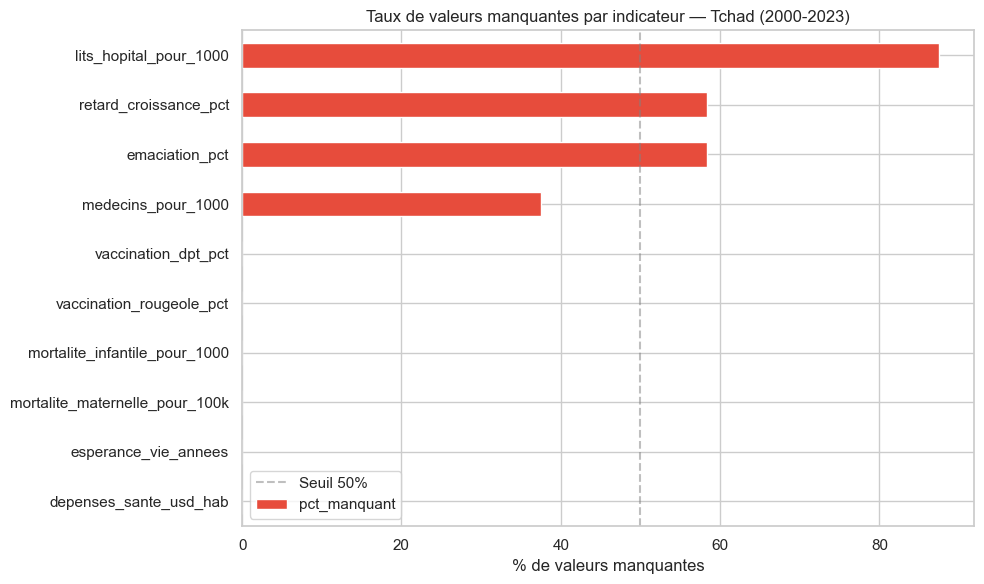

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
pivot_missing.sort_values('pct_manquant').plot.barh(
    y='pct_manquant', ax=ax, color='#e74c3c', legend=False
)
ax.set_xlabel('% de valeurs manquantes')
ax.set_ylabel('')
ax.set_title('Taux de valeurs manquantes par indicateur — Tchad (2000-2023)')
ax.axvline(x=50, color='gray', linestyle='--', alpha=0.5, label='Seuil 50%')
ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / '01_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Nettoyage des données

### 4.1 Vérification des doublons

In [28]:
df = df_raw.copy()

dupes = df.duplicated(subset=['nom_indicateur', 'annee']).sum()
print(f'Doublons (indicateur + année): {dupes}')

if dupes > 0:
    df = df.drop_duplicates(subset=['nom_indicateur', 'annee'], keep='first')
    print(f'Doublons supprimés. Nouvelles dimensions: {df.shape}')

Doublons (indicateur + année): 0


### 4.2 Standardisation des types

In [29]:
df['annee'] = pd.to_numeric(df['annee'], errors='coerce').astype('Int64')
df['valeur'] = pd.to_numeric(df['valeur'], errors='coerce')

print('Types après standardisation:')
print(df[['annee', 'valeur']].dtypes)
print(f'\nPlage des années: {df["annee"].min()} — {df["annee"].max()}')

Types après standardisation:
annee       Int64
valeur    float64
dtype: object

Plage des années: 2000 — 2023


### 4.3 Traitement des valeurs manquantes

Stratégie adaptée au contexte des séries temporelles sanitaires :
- **Interpolation linéaire** pour les indicateurs avec au moins 5 valeurs connues (les indicateurs de santé évoluent progressivement)
- **Pas d'imputation** pour les indicateurs avec trop peu de données (< 5 valeurs) — on les signale comme lacunaires

In [30]:
missing_before = df['valeur'].isnull().sum()
was_null = df['valeur'].isnull().copy()

parts = []
for name, group in df.groupby('nom_indicateur'):
    group = group.sort_values('annee').copy()
    if group['valeur'].notna().sum() >= 5:
        group['valeur'] = group['valeur'].interpolate(method='linear', limit_direction='both')
    parts.append(group)

df = pd.concat(parts, ignore_index=True)
df['impute'] = was_null.values & df['valeur'].notna().values

missing_after = df['valeur'].isnull().sum()
imputed = df['impute'].sum()

print(f'Valeurs manquantes avant: {missing_before}')
print(f'Valeurs imputées (interpolation): {imputed}')
print(f'Valeurs manquantes après: {missing_after}')
if missing_before > 0:
    print(f'Réduction: {((missing_before - missing_after) / missing_before * 100):.1f}%')

print(f'\nColonnes disponibles: {list(df.columns)}')

Valeurs manquantes avant: 58
Valeurs imputées (interpolation): 58
Valeurs manquantes après: 21
Réduction: 63.8%

Colonnes disponibles: ['pays', 'code_pays', 'annee', 'code_indicateur', 'indicateur', 'valeur', 'nom_indicateur', 'impute']


### 4.4 Détection des outliers (méthode IQR)

In [31]:
parts = []
for name, group in df.groupby('nom_indicateur'):
    group = group.copy()
    values = group['valeur'].dropna()
    if len(values) < 4:
        group['outlier'] = False
    else:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        group['outlier'] = group['valeur'].apply(
            lambda x: (x < lower or x > upper) if pd.notna(x) else False
        )
    parts.append(group)

df = pd.concat(parts, ignore_index=True)

outlier_count = df['outlier'].sum()
print(f'Outliers détectés (IQR): {outlier_count}')

if outlier_count > 0:
    print('\nDétail par indicateur:')
    for name, group in df[df['outlier']].groupby('nom_indicateur'):
        years = group['annee'].tolist()
        print(f'  {name}: années {years}')

Outliers détectés (IQR): 11

Détail par indicateur:
  depenses_sante_usd_hab: années [2000, 2001, 2021, 2022, 2023]
  emaciation_pct: années [2022, 2023]
  medecins_pour_1000: années [2022, 2023]
  mortalite_maternelle_pour_100k: années [2022, 2023]


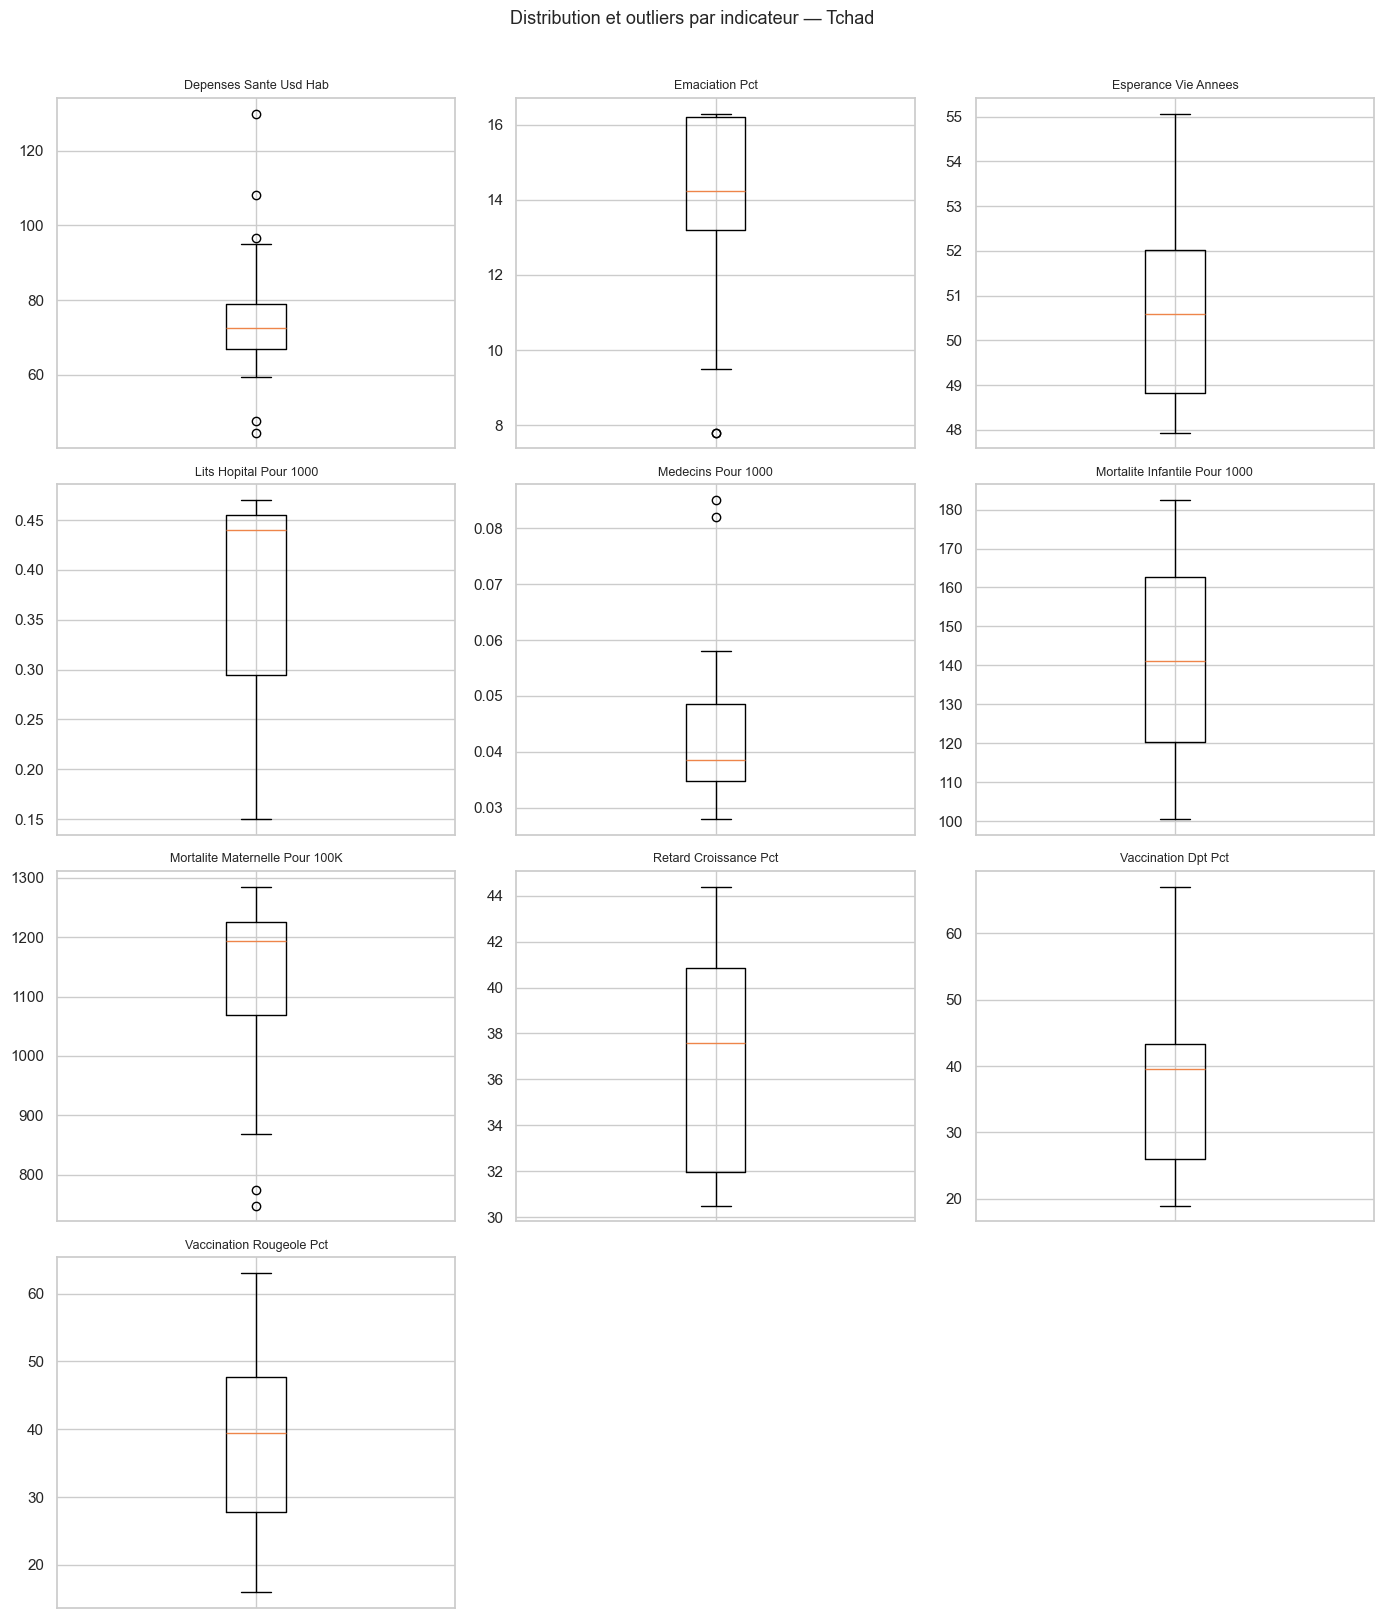

In [32]:
indicators_with_data = df[df['valeur'].notna()]['nom_indicateur'].unique()
n_indicators = len(indicators_with_data)
ncols = 3
nrows = (n_indicators + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axes = axes.flatten()

for i, ind in enumerate(sorted(indicators_with_data)):
    subset = df[df['nom_indicateur'] == ind].dropna(subset=['valeur'])
    axes[i].boxplot(subset['valeur'], vert=True)
    axes[i].set_title(ind.replace('_', ' ').title(), fontsize=9)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribution et outliers par indicateur — Tchad', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(IMG_DIR / '02_boxplots_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5 Validation de cohérence

Vérifications logiques sur les données de santé :
- Les pourcentages doivent être entre 0 et 100
- Les ratios (médecins, lits) doivent être positifs
- La mortalité ne peut pas être négative

In [33]:
pct_indicators = [
    'retard_croissance_pct', 'emaciation_pct',
    'vaccination_rougeole_pct', 'vaccination_dpt_pct'
]
positive_indicators = list(INDICATORS.values())

issues = []

for ind in pct_indicators:
    mask = df['nom_indicateur'] == ind
    out_of_range = df[mask & ((df['valeur'] < 0) | (df['valeur'] > 100))]
    if len(out_of_range) > 0:
        issues.append(f'{ind}: {len(out_of_range)} valeurs hors [0, 100]')

for ind in positive_indicators:
    mask = df['nom_indicateur'] == ind
    negative = df[mask & (df['valeur'] < 0)]
    if len(negative) > 0:
        issues.append(f'{ind}: {len(negative)} valeurs négatives')

if issues:
    print('Problèmes de cohérence détectés:')
    for issue in issues:
        print(f'  ⚠ {issue}')
else:
    print('✓ Aucun problème de cohérence détecté')

✓ Aucun problème de cohérence détecté


## 5. Restructuration et export

In [34]:
df_wide = df.pivot_table(
    index='annee',
    columns='nom_indicateur',
    values='valeur'
).reset_index()

df_wide.columns.name = None
df_wide = df_wide.sort_values('annee').reset_index(drop=True)

print(f'Dataset nettoyé: {df_wide.shape[0]} lignes × {df_wide.shape[1]} colonnes')
df_wide.head(10)

Dataset nettoyé: 24 lignes × 11 colonnes


,annee,depenses_sante_usd_hab,emaciation_pct,esperance_vie_annees,lits_hopital_pour_1000,medecins_pour_1000,mortalite_infantile_pour_1000,mortalite_maternelle_pour_100k,retard_croissance_pct,vaccination_dpt_pct,vaccination_rougeole_pct
0,2000,44.517328,13.900000,47.937,NaN,0.02800,182.4,1208.0,38.900,38.0,28.0
1,2001,47.661988,14.475000,48.306,NaN,0.02975,179.0,1204.0,40.275,26.0,26.0
2,2002,69.633348,15.050000,48.360,NaN,0.03150,175.6,1199.0,41.650,25.0,25.0
3,2003,59.320580,15.625000,48.609,NaN,0.03325,172.3,1170.0,43.025,23.0,23.0
4,2004,77.736823,16.200000,48.687,NaN,0.03500,168.8,1167.0,44.400,22.0,16.0
5,2005,73.453088,16.216667,48.860,NaN,0.03450,165.4,1189.0,43.450,26.0,27.0
6,2006,73.860202,16.233333,48.747,NaN,0.03400,161.8,1220.0,42.500,41.0,39.0
7,2007,67.632828,16.250000,49.210,NaN,0.03500,158.1,1240.0,41.550,29.0,31.0
8,2008,64.084012,16.266667,49.503,NaN,0.03600,154.3,1264.0,40.600,19.0,27.0
9,2009,70.950173,16.283333,49.828,NaN,0.03700,150.5,1285.0,39.650,26.0,36.0


In [35]:
df_wide.to_csv(CLEAN_DIR / 'chad_health_indicators_clean.csv', index=False)

df.to_csv(CLEAN_DIR / 'chad_health_indicators_long.csv', index=False)

print(f'Fichiers exportés:')
print(f'  → {CLEAN_DIR / "chad_health_indicators_clean.csv"} (format large)')
print(f'  → {CLEAN_DIR / "chad_health_indicators_long.csv"} (format long)')

Fichiers exportés:
  → ..\dataset\cleaned\chad_health_indicators_clean.csv (format large)
  → ..\dataset\cleaned\chad_health_indicators_long.csv (format long)


## 6. Rapport de qualité des données

In [36]:
total_cells_raw = len(df_raw)
missing_raw = df_raw['valeur'].isnull().sum()
total_cells_clean = len(df)
missing_clean = df['valeur'].isnull().sum()

report = pd.DataFrame({
    'Métrique': [
        'Lignes totales',
        'Indicateurs',
        'Années couvertes',
        'Valeurs manquantes',
        '% manquant',
        'Doublons supprimés',
        'Valeurs imputées',
        'Outliers détectés'
    ],
    'Avant nettoyage': [
        total_cells_raw,
        df_raw['nom_indicateur'].nunique(),
        f"{df_raw['annee'].min()}-{df_raw['annee'].max()}",
        missing_raw,
        f'{missing_raw / total_cells_raw * 100:.1f}%',
        dupes,
        '—',
        '—'
    ],
    'Après nettoyage': [
        total_cells_clean,
        df['nom_indicateur'].nunique(),
        f"{df['annee'].min()}-{df['annee'].max()}",
        missing_clean,
        f'{missing_clean / total_cells_clean * 100:.1f}%',
        0,
        imputed,
        outlier_count
    ]
})

print('═══════════════════════════════════════════')
print('  RAPPORT DE QUALITÉ — Indicateurs Santé Tchad')
print('═══════════════════════════════════════════')
print(report.to_string(index=False))

═══════════════════════════════════════════
  RAPPORT DE QUALITÉ — Indicateurs Santé Tchad
═══════════════════════════════════════════
          Métrique Avant nettoyage Après nettoyage
    Lignes totales             240             240
       Indicateurs              10              10
  Années couvertes       2000-2023       2000-2023
Valeurs manquantes              58              21
        % manquant           24.2%            8.8%
Doublons supprimés               0               0
  Valeurs imputées               —              58
 Outliers détectés               —              11


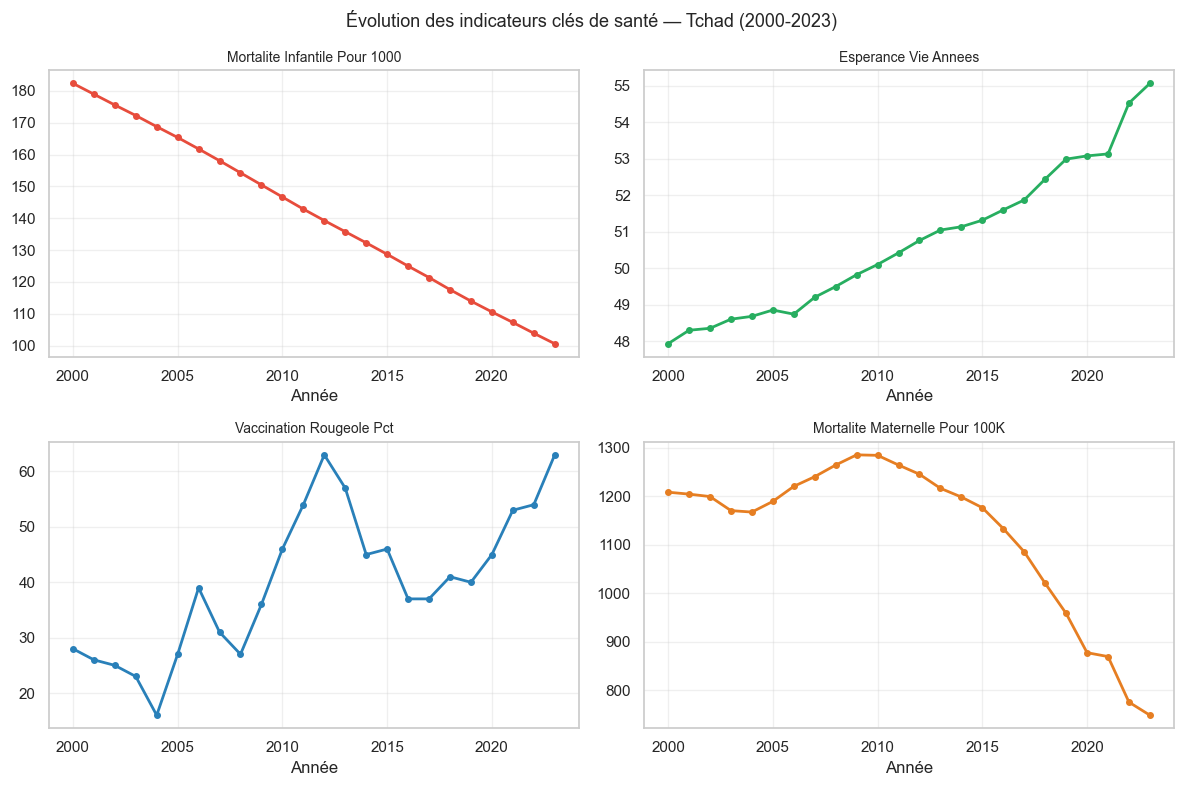

In [37]:
key_indicators = [
    'mortalite_infantile_pour_1000',
    'esperance_vie_annees',
    'vaccination_rougeole_pct',
    'mortalite_maternelle_pour_100k'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

colors = ['#e74c3c', '#27ae60', '#2980b9', '#e67e22']

for i, ind in enumerate(key_indicators):
    subset = df_wide[['annee', ind]].dropna()
    if subset.empty:
        axes[i].text(0.5, 0.5, 'Données insuffisantes', ha='center', va='center')
        axes[i].set_title(ind.replace('_', ' ').title(), fontsize=10)
        continue
    axes[i].plot(subset['annee'], subset[ind], color=colors[i], linewidth=2, marker='o', markersize=4)
    axes[i].set_title(ind.replace('_', ' ').title(), fontsize=10)
    axes[i].set_xlabel('Année')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Évolution des indicateurs clés de santé — Tchad (2000-2023)', fontsize=13)
plt.tight_layout()
plt.savefig(IMG_DIR / '03_trends_key_indicators.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Conclusion

### Actions réalisées
1. **Collecte** de 10 indicateurs de santé via l'API Banque Mondiale
2. **Nettoyage** : suppression des doublons, standardisation des types, interpolation des valeurs manquantes
3. **Validation** : vérification de cohérence (plages, signes, logique sanitaire)
4. **Export** : dataset nettoyé en formats large et long

### Observations sur les données du Tchad
- Fort taux de valeurs manquantes pour certains indicateurs (médecins, lits d'hôpital) — reflète la faiblesse du système statistique
- Tendances positives sur la mortalité infantile et la vaccination
- Les données sur les ressources humaines de santé (médecins, lits) sont les plus lacunaires

### Limites
- L'interpolation linéaire suppose une évolution régulière, ce qui peut ne pas refléter les chocs (crises, épidémies)
- Les outliers détectés ne sont pas nécessairement des erreurs — ils peuvent refléter des changements réels de politique sanitaire
- Les données les plus récentes sont souvent des estimations, pas des mesures directes